# ChipWhisperer-Nano: AES-128 Correlation Power Analysis

**Objective:** Capture physical power traces from the ChipWhisperer-Nano's built-in STM32F030 target and use correlation power analysis (CPA) to recover an AES-128 test key.

**Hardware:** ChipWhisperer-Nano (integrated STM32F030 target; no external target board required).  
**Software:** NewAE ChipWhisperer, Python/Jupyter, and an ARM cross-compiler. On Windows, the firmware build is run using Ubuntu/WSL.  
**Leakage hypothesis:** Hamming weight of the first-round AES S-box output, $\operatorname{HW}(\operatorname{SBOX}(p\oplus k))$.

### Workflow

1. Configure paths to the project repository and the NewAE ChipWhisperer source installation.
2. Build and flash TinyAES firmware for the Nano.
3. Verify AES encryption against known-answer test vectors.
4. Acquire power traces for all-zero and nonzero fixed test keys.
5. Perform CPA to recover AES-128 key bytes.
6. Plot the number of recovered key bytes versus the number of traces.

This is a controlled educational exercise on an intentionally unprotected AES implementation, not a new cryptanalytic attack. **Results and plots are produced when the code cells are executed on physical hardware.**


## 1. Configure the repository and ChipWhisperer source directory

Run this notebook from the root of the `chipwhisperer-nano-AES-cpa` repository. Jupyter normally launches each notebook's kernel in the notebook's folder. Alternatively, set the `AES_CPA_REPO_ROOT` environment variable before starting the kernel.

The NewAE ChipWhisperer source directory is **separate from this repository** and contains `firmware/mcu/simpleserial-aes/Makefile`. The default `CW_SOURCE` below uses the user's home directory; adjust it or set `CHIPWHISPERER_SOURCE` to match your installation.

Captured traces are saved in `data/` and figures in `results/`, both within the repository. The configuration cell avoids printing absolute local paths.


In [1]:
import os
import shlex
import subprocess
import secrets
from pathlib import Path

import chipwhisperer as cw
import chipwhisperer.analyzer as cwa
import matplotlib.pyplot as plt
import numpy as np

# Repository containing this notebook, README.md, and docs/experiment_setup.md.
REPO_ROOT = Path(
    os.environ.get('AES_CPA_REPO_ROOT', str(Path.cwd()))
).expanduser().resolve()

# Separately installed NewAE ChipWhisperer firmware source tree.
CW_SOURCE = Path(
    os.environ.get('CHIPWHISPERER_SOURCE', str(Path.home() / 'ChipWhisperer' / 'chipwhisperer'))
).expanduser().resolve()

if (
    REPO_ROOT == CW_SOURCE
    or not (REPO_ROOT / 'README.md').is_file()
    or not (REPO_ROOT / 'docs' / 'experiment_setup.md').is_file()
):
    raise RuntimeError(
        'Project root not found. Open this notebook from the '
        'chipwhisperer-nano-AES-cpa repository folder, or set '
        'AES_CPA_REPO_ROOT to that folder.'
    )

FIRMWARE_DIR = CW_SOURCE / 'firmware' / 'mcu' / 'simpleserial-aes'
FIRMWARE_HEX = FIRMWARE_DIR / 'simpleserial-aes-CWNANO.hex'
if not (FIRMWARE_DIR / 'Makefile').is_file():
    raise FileNotFoundError(
        'ChipWhisperer firmware Makefile not found. '
        'Set CHIPWHISPERER_SOURCE to the directory containing '
        'firmware/mcu/simpleserial-aes.'
    )

DATA_DIR = REPO_ROOT / 'data'
RESULTS_DIR = REPO_ROOT / 'results'
DATA_DIR.mkdir(exist_ok=True)
RESULTS_DIR.mkdir(exist_ok=True)

print('Project directory verified')
print('ChipWhisperer firmware source located')
print('ChipWhisperer version:', getattr(cw, '__version__', 'unknown'))
print('NumPy version:', np.__version__)


Project directory verified
ChipWhisperer firmware source located
ChipWhisperer version: 6.0.0
NumPy version: 1.26.4


## 2. Build AES-128 firmware for the Nano

The firmware uses NewAE's `simpleserial-aes` example with `TINYAES128C` and SimpleSerial 1.1. On Windows, the ARM cross-compiler runs under Ubuntu/WSL. On Linux or macOS, the build runs directly using an installed ARM toolchain.

Set `CHIPWHISPERER_WSL_DISTRO` if your WSL distribution is not named `Ubuntu`.


In [2]:
BUILD_OPTIONS = ['PLATFORM=CWNANO', 'CRYPTO_TARGET=TINYAES128C', 'SS_VER=SS_VER_1_1', '-j2']

if os.name == 'nt':
    WSL_DISTRO = os.environ.get('CHIPWHISPERER_WSL_DISTRO', 'Ubuntu')
    if not FIRMWARE_DIR.drive or not FIRMWARE_DIR.drive[0].isalpha():
        raise RuntimeError('WSL build requires a firmware source tree on a local Windows drive.')
    relative_path = FIRMWARE_DIR.relative_to(FIRMWARE_DIR.anchor).as_posix()
    firmware_dir_wsl = f'/mnt/{FIRMWARE_DIR.drive[0].lower()}/{relative_path}'
    command = f'cd {shlex.quote(firmware_dir_wsl)} && make ' + ' '.join(BUILD_OPTIONS)
    argv = ['wsl.exe', '-d', WSL_DISTRO, '--exec', '/bin/bash', '-lc', command]
else:
    argv = ['make', *BUILD_OPTIONS]

build = subprocess.run(
    argv,
    cwd=None if os.name == 'nt' else str(FIRMWARE_DIR),
    capture_output=True,
    text=True,
    errors='replace',
)
# Build logs can contain local directory names. Show only the final status;
# inspect build.stdout and build.stderr privately if troubleshooting is needed.
if build.returncode != 0:
    raise RuntimeError('Firmware build failed. Check the build logs locally before publishing.')
if not FIRMWARE_HEX.is_file():
    raise FileNotFoundError('Firmware binary was not created by the build.')
print('Firmware compiled: simpleserial-aes-CWNANO.hex')


Firmware compiled: simpleserial-aes-CWNANO.hex


## 3. Program the integrated target and verify AES-128

Connect the ChipWhisperer-Nano over USB. Program the integrated target and verify AES-128 using a known-answer test with an all-zero key and plaintext. Explicit key transfer ensures the target uses the intended test key.


In [3]:
scope = cw.scope()
scope.default_setup()

cw.program_target(scope, cw.programmers.STM32FProgrammer, str(FIRMWARE_HEX))
target = cw.target(scope, cw.targets.SimpleSerial)

print('Connected to:', type(scope).__name__)
print('Nano target programmed and SimpleSerial initialized.')


Detected known STMF32: STM32F04xxx
Extended erase (0x44), this can take ten seconds or more
Attempting to program 6199 bytes at 0x8000000
STM32F Programming flash...
STM32F Reading flash...
Verified flash OK, 6199 bytes
Connected to: CWNano
Nano target programmed and SimpleSerial initialized.


Expected ciphertext: 66e94bd4ef8a2c3b884cfa59ca342b2e
Actual ciphertext:   66e94bd4ef8a2c3b884cfa59ca342b2e
AES ciphertext correct: True
Samples: 5000


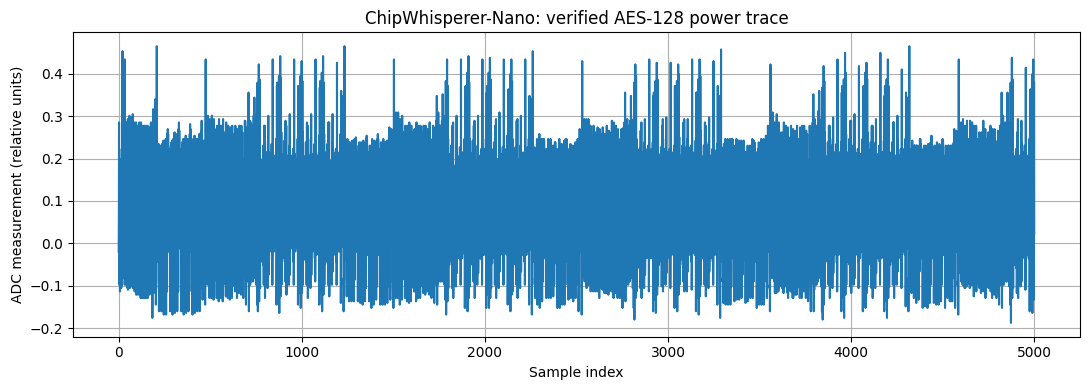

In [4]:
zero_key = bytearray(16)
zero_plaintext = bytearray(16)
zero_expected = '66e94bd4ef8a2c3b884cfa59ca342b2e'

# Always send the requested key rather than relying on previous device state.
target.set_key(zero_key, always_send=True)
verified_trace = cw.capture_trace(
    scope, target, zero_plaintext, zero_key, always_send_key=True
)
if verified_trace is None or verified_trace.textout is None:
    raise RuntimeError('AES known-answer capture failed')

zero_actual = bytes(verified_trace.textout).hex()
print('Expected ciphertext:', zero_expected)
print('Actual ciphertext:  ', zero_actual)
assert zero_actual == zero_expected, 'AES test vector verification failed'
print('AES ciphertext correct: True')
print('Samples:', len(verified_trace.wave))

plt.figure(figsize=(11, 4))
plt.plot(verified_trace.wave)
plt.title('ChipWhisperer-Nano: verified AES-128 power trace')
plt.xlabel('Sample index')
plt.ylabel('ADC measurement (relative units)')
plt.grid(True)
plt.tight_layout()
plt.savefig(RESULTS_DIR / 'verified_aes_trace.png', dpi=150)
plt.show()


## 4. Capture 100 traces with an all-zero test key

Acquire 100 independent encryptions with **random plaintexts** and the same fixed laboratory key. Store *actual measured* traces in a NumPy archive under `data/`. Figures are generated from the captured data.


Captured 20/100 zero-key traces
Captured 40/100 zero-key traces
Captured 60/100 zero-key traces
Captured 80/100 zero-key traces
Captured 100/100 zero-key traces
Dataset shape: (100, 5000)
Saved: data/aes_100_traces.npz


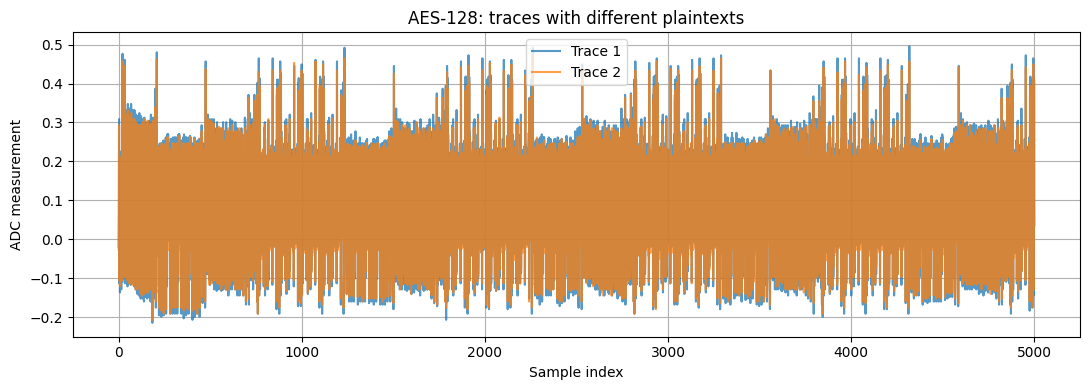

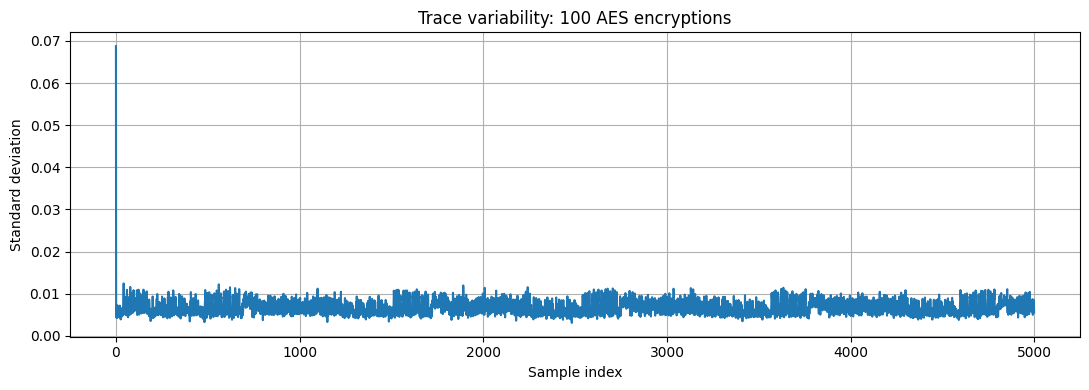

In [5]:
N = 100
waves_zero, plaintexts_zero, ciphertexts_zero = [], [], []

for i in range(N):
    pt = bytearray(secrets.token_bytes(16))
    trace = cw.capture_trace(scope, target, pt, zero_key, always_send_key=True)
    if trace is None or trace.textout is None:
        raise RuntimeError(f'Zero-key capture {i + 1} failed')

    waves_zero.append(np.asarray(trace.wave, dtype=float))
    plaintexts_zero.append(np.frombuffer(pt, dtype=np.uint8).copy())
    ciphertexts_zero.append(np.frombuffer(bytes(trace.textout), dtype=np.uint8).copy())

    if (i + 1) % 20 == 0:
        print(f'Captured {i + 1}/{N} zero-key traces')

waves_zero = np.stack(waves_zero)
plaintexts_zero = np.stack(plaintexts_zero)
ciphertexts_zero = np.stack(ciphertexts_zero)

np.savez_compressed(
    DATA_DIR / 'aes_100_traces.npz',
    waves=waves_zero,
    plaintexts=plaintexts_zero,
    ciphertexts=ciphertexts_zero,
    key=np.asarray(zero_key, dtype=np.uint8),
)
print('Dataset shape:', waves_zero.shape)
print('Saved: data/aes_100_traces.npz')

plt.figure(figsize=(11, 4))
plt.plot(waves_zero[0], label='Trace 1', alpha=0.75)
plt.plot(waves_zero[1], label='Trace 2', alpha=0.75)
plt.xlabel('Sample index')
plt.ylabel('ADC measurement')
plt.title('AES-128: traces with different plaintexts')
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.savefig(RESULTS_DIR / 'power_traces.png', dpi=150)
plt.show()

plt.figure(figsize=(11, 4))
plt.plot(np.std(waves_zero, axis=0))
plt.xlabel('Sample index')
plt.ylabel('Standard deviation')
plt.title('Trace variability: 100 AES encryptions')
plt.grid(True)
plt.tight_layout()
plt.savefig(RESULTS_DIR / 'trace_variability.png', dpi=150)
plt.show()


## 5. Recover the all-zero test key using CPA

For each key-byte hypothesis $k$, predict the Hamming weight of the first AES S-box output for each known plaintext byte $p$: $L(p,k)=\operatorname{HW}(\operatorname{SBOX}(p\oplus k))$. Pearson correlation against each measured power sample ranks candidate key values.

The ChipWhisperer analyzer is invoked with `cwa.cpa(...)` and `cwa.leakage_models.sbox_output`.


In [6]:
project_zero = cw.create_project(str(DATA_DIR / 'nano_aes_zero_key.cwp'), overwrite=True)
for i in range(len(waves_zero)):
    project_zero.traces.append(
        cw.Trace(
            waves_zero[i],
            bytearray(plaintexts_zero[i]),
            bytearray(ciphertexts_zero[i]),
            bytearray(zero_key),
        )
    )
project_zero.save()

attack_zero = cwa.cpa(project_zero, cwa.leakage_models.sbox_output)
attack_zero.subkey_list = list(range(16))
results_zero = attack_zero.run(update_interval=25)
guesses_zero = results_zero.key_guess()

recovered_zero = ''.join(
    f'{int(g):02x}' if g is not None else '??' for g in guesses_zero
)
correct_zero = sum(
    g is not None and int(g) == zero_key[i]
    for i, g in enumerate(guesses_zero[:16])
)
print('Expected key:', zero_key.hex())
print('Recovered key:', recovered_zero)
print(f'Correctly recovered: {correct_zero}/16 bytes')


Expected key: 00000000000000000000000000000000
Recovered key: 00000000000000000000000000000000
Correctly recovered: 16/16 bytes


## 6. Verify a nonzero AES test key, then capture 100 traces

Use the FIPS 197 example key `000102030405060708090a0b0c0d0e0f` and plaintext `00112233445566778899aabbccddeeff`; the expected ciphertext is `69c4e0d86a7b0430d8cdb78070b4c55a`.


In [7]:
nonzero_key = bytearray.fromhex('000102030405060708090a0b0c0d0e0f')
nonzero_plaintext = bytearray.fromhex('00112233445566778899aabbccddeeff')
nonzero_expected = '69c4e0d86a7b0430d8cdb78070b4c55a'

target.set_key(nonzero_key, always_send=True)
test_trace = cw.capture_trace(
    scope, target, nonzero_plaintext, nonzero_key, always_send_key=True
)
if test_trace is None or test_trace.textout is None:
    raise RuntimeError('Nonzero-key AES verification capture failed')
assert bytes(test_trace.textout).hex() == nonzero_expected, 'FIPS-197 vector failed'
print('AES ciphertext correct: True')

N = 100
project_nonzero = cw.create_project(str(DATA_DIR / 'nano_aes_nonzero_key.cwp'), overwrite=True)

for i in range(N):
    pt = bytearray(secrets.token_bytes(16))
    trace = cw.capture_trace(scope, target, pt, nonzero_key, always_send_key=True)
    if trace is None or trace.textout is None:
        raise RuntimeError(f'Nonzero-key capture {i + 1} failed')
    project_nonzero.traces.append(trace)
    if (i + 1) % 20 == 0:
        print(f'Captured {i + 1}/{N} nonzero-key traces')

project_nonzero.save()
nonzero_traces = list(project_nonzero.traces)
waves_nonzero = np.stack([np.asarray(t.wave) for t in nonzero_traces])
plaintexts_nonzero = np.stack([np.asarray(t.textin, dtype=np.uint8) for t in nonzero_traces])
ciphertexts_nonzero = np.stack([np.asarray(t.textout, dtype=np.uint8) for t in nonzero_traces])
np.savez_compressed(
    DATA_DIR / 'aes_100_traces_nonzero_key.npz',
    waves=waves_nonzero,
    plaintexts=plaintexts_nonzero,
    ciphertexts=ciphertexts_nonzero,
    key=np.asarray(nonzero_key, dtype=np.uint8),
)
print('Nonzero-key dataset:', waves_nonzero.shape)
print('Saved: data/aes_100_traces_nonzero_key.npz')


AES ciphertext correct: True
Captured 20/100 nonzero-key traces
Captured 40/100 nonzero-key traces
Captured 60/100 nonzero-key traces
Captured 80/100 nonzero-key traces
Captured 100/100 nonzero-key traces
Nonzero-key dataset: (100, 5000)
Saved: data/aes_100_traces_nonzero_key.npz


## 7. Recover the nonzero AES key

Use the same first-round S-box leakage hypothesis on the new measured dataset. Results can differ across independently captured datasets due to measurement noise.


In [8]:
attack_nonzero = cwa.cpa(project_nonzero, cwa.leakage_models.sbox_output)
attack_nonzero.subkey_list = list(range(16))
results_nonzero = attack_nonzero.run(update_interval=25)
guesses_nonzero = results_nonzero.key_guess()

recovered_nonzero = ''.join(
    f'{int(g):02x}' if g is not None else '??' for g in guesses_nonzero
)
correct_nonzero = sum(
    g is not None and int(g) == nonzero_key[i]
    for i, g in enumerate(guesses_nonzero[:16])
)
print('Expected key:', nonzero_key.hex())
print('Recovered key:', recovered_nonzero)
print(f'Correctly recovered: {correct_nonzero}/16 bytes')


Expected key: 000102030405060708090a0b0c0d0e0f
Recovered key: 000102030405060708090a0b0c0d0e0f
Correctly recovered: 16/16 bytes


## 8. Study recovery as the number of traces increases

For this single capture dataset, run CPA on successively longer **prefixes of the same 100 traces**. This measures recovery for one dataset, **not** a statistical success probability or guaranteed minimum trace count. Very small trace counts may produce zero-variance correlation warnings; do not hide them.


10 traces - RuntimeWarning: invalid value encountered in divide
 10 traces: 2/16 bytes recovered
 20 traces: 11/16 bytes recovered
 30 traces: 15/16 bytes recovered
 40 traces: 16/16 bytes recovered
 50 traces: 16/16 bytes recovered
 60 traces: 16/16 bytes recovered
 80 traces: 16/16 bytes recovered
100 traces: 16/16 bytes recovered


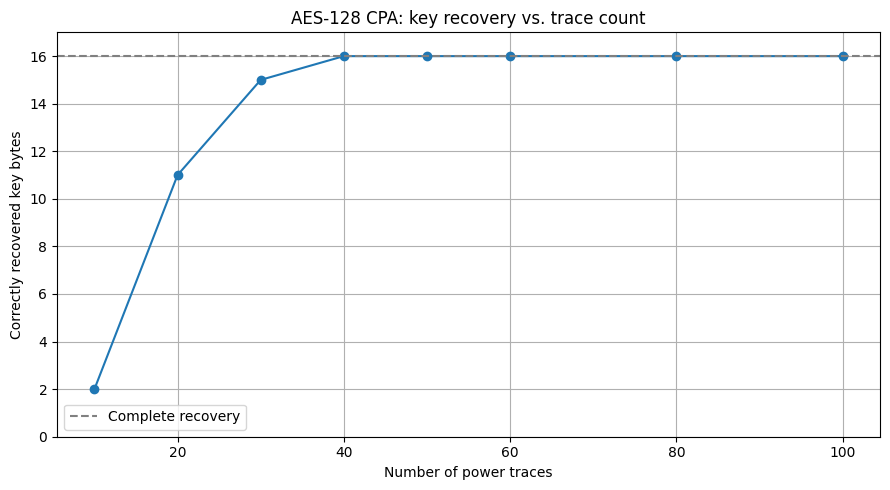

In [9]:
import warnings

trace_counts = [10, 20, 30, 40, 50, 60, 80, 100]
recovery_counts = []

for n in trace_counts:
    attack_prefix = cwa.cpa(project_nonzero, cwa.leakage_models.sbox_output)
    attack_prefix.subkey_list = list(range(16))
    attack_prefix.trace_range = [0, n]
    # Show numerical warnings without disclosing local Python installation paths.
    with warnings.catch_warnings(record=True) as recorded_warnings:
        warnings.simplefilter('always', RuntimeWarning)
        prefix_results = attack_prefix.run(update_interval=25)
    if recorded_warnings:
        messages = sorted(set(
            f'{w.category.__name__}: {w.message}' for w in recorded_warnings
        ))
        print(f'{n} traces - ' + '; '.join(messages))
    prefix_guesses = prefix_results.key_guess()

    correct = sum(
        prefix_guesses[i] is not None and int(prefix_guesses[i]) == nonzero_key[i]
        for i in range(16)
    )
    recovery_counts.append(correct)
    print(f'{n:3d} traces: {correct}/16 bytes recovered')

plt.figure(figsize=(9, 5))
plt.plot(trace_counts, recovery_counts, marker='o')
plt.axhline(16, linestyle='--', color='gray', label='Complete recovery')
plt.xlabel('Number of power traces')
plt.ylabel('Correctly recovered key bytes')
plt.title('AES-128 CPA: key recovery vs. trace count')
plt.yticks(range(0, 17, 2))
plt.ylim(0, 17)
plt.grid(True)
plt.legend()
plt.tight_layout()
plt.savefig(RESULTS_DIR / 'key_recovery_vs_traces.png', dpi=150)
plt.show()


## 9. Disconnect when finished

Run this cell at the end of the experiment to release the target and capture device. If restarting the notebook after disconnecting, rerun the connection/programming cell before taking new measurements.


In [10]:
target.dis()
scope.dis()
print('Disconnected from ChipWhisperer-Nano.')


Disconnected from ChipWhisperer-Nano.


## Experiment scope and reproducibility

- **Hardware:** ChipWhisperer-Nano, using its integrated STM32F030 target. The firmware and CPA analysis rely on [NewAE ChipWhisperer](https://github.com/newaetech/chipwhisperer).
- **Datasets:** Each capture run collects 100 physical power traces with new random plaintexts and a fixed, known laboratory key. The measurements are saved under `data/`.
- **Results:** Key recovery, correlation scores, and trace-count curves depend on the newly captured traces and may vary across runs. The trace-count curve uses prefixes from a single capture set and is not a statistical success-rate estimate.
- **Reproducibility:** Python and ChipWhisperer versions are printed when the configuration cell executes. The machine's firmware source directory can be configured using `CHIPWHISPERER_SOURCE`.
- **Release hygiene:** Before committing executed notebooks, review saved cell outputs, warnings, and tracebacks for local directory paths or identifiers. Never claim a result from a run that did not complete successfully.
- **Security scope:** The target runs an unprotected educational AES implementation. Results do not imply that the attack succeeds against protected or production systems.

See [Experiment setup](docs/experiment_setup.md) for the installation and firmware build procedure and [NIST FIPS 197](https://csrc.nist.gov/pubs/fips/197/final) for AES-128.
